In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer

project_root = Path.cwd()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import calculate_metrics, compute_confusion_matrix, export_error_analysis


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

LABELS = ["negative", "neutral", "positive"]

id_to_label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"
models_dir = project_root / "models"
metrics_dir = project_root / "outputs" / "metrics"
predictions_dir = project_root / "outputs" / "predictions"
figures_dir = project_root / "outputs" / "figures"

for folder in [metrics_dir, predictions_dir, figures_dir]:
    folder.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(processed_dir / "test.csv")

model_path = models_dir / "distilbert_financial_sentiment"

print("Test examples:", len(test_df))
print("Saved model location:", model_path)

Test examples: 726
Saved model location: c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\models\distilbert_financial_sentiment


In [3]:
tokenizer = AutoTokenizer.from_pretrained(model_path)

model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

test_dataset = Dataset.from_pandas(
    test_df[
        ["sentence", "label_id"]
    ].rename(columns={"label_id": "labels"}),
    preserve_index=False
)

def tokenize_function(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map: 100%|██████████| 726/726 [00:00<00:00, 4252.01 examples/s]


In [4]:

evaluation_args = TrainingArguments(
    output_dir=str(models_dir / "test_evaluation"),
    per_device_eval_batch_size=16,
    report_to="none"
)

evaluator = Trainer(
    model=model,
    args=evaluation_args,
    data_collator=data_collator,
    processing_class=tokenizer
)

test_output = evaluator.predict(tokenized_test)

test_logits = test_output.predictions
test_predicted_ids = np.argmax(test_logits, axis=1)

shifted_logits = test_logits - np.max(
    test_logits,
    axis=1,
    keepdims=True
)

test_probabilities = np.exp(shifted_logits)
test_probabilities = test_probabilities / test_probabilities.sum(
    axis=1,
    keepdims=True
)

print("Completed final test predictions.")

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Completed final test predictions.


In [5]:

finetuned_test_predictions = test_df.copy()

finetuned_test_predictions["predicted_label"] = [
    id_to_label[prediction]
    for prediction in test_predicted_ids
]

finetuned_test_predictions["confidence"] = test_probabilities.max(axis=1)

finetuned_test_predictions["negative_probability"] = test_probabilities[:, 0]
finetuned_test_predictions["neutral_probability"] = test_probabilities[:, 1]
finetuned_test_predictions["positive_probability"] = test_probabilities[:, 2]

display(
    finetuned_test_predictions[
        [
            "sentence",
            "label",
            "predicted_label",
            "confidence"
        ]
    ].head()
)

,sentence,label,predicted_label,confidence
0,"While I cant understand what theyre saying , i...",neutral,positive,0.574994
1,More than a third of the original participants...,negative,negative,0.853642
2,Solidium now holds 5.0 per cent of the shares ...,neutral,neutral,0.968972
3,"Following the divestment , Fiskars 's Outdoor ...",neutral,neutral,0.976401
4,"Also , a six-year historic analysis is provide...",neutral,neutral,0.975056


In [6]:

finetuned_accuracy = accuracy_score(
    finetuned_test_predictions["label"],
    finetuned_test_predictions["predicted_label"]
)

finetuned_macro_f1 = f1_score(
    finetuned_test_predictions["label"],
    finetuned_test_predictions["predicted_label"],
    labels=LABELS,
    average="macro",
    zero_division=0
)

finetuned_report = classification_report(
    finetuned_test_predictions["label"],
    finetuned_test_predictions["predicted_label"],
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

print(f"Fine-tuned test accuracy: {finetuned_accuracy:.3f}")
print(f"Fine-tuned test macro F1: {finetuned_macro_f1:.3f}")

for label in LABELS:
    print(
        f"{label.capitalize()} F1: "
        f"{finetuned_report[label]['f1-score']:.3f}"
    )

Fine-tuned test accuracy: 0.854
Fine-tuned test macro F1: 0.839
Negative F1: 0.839
Neutral F1: 0.887
Positive F1: 0.790


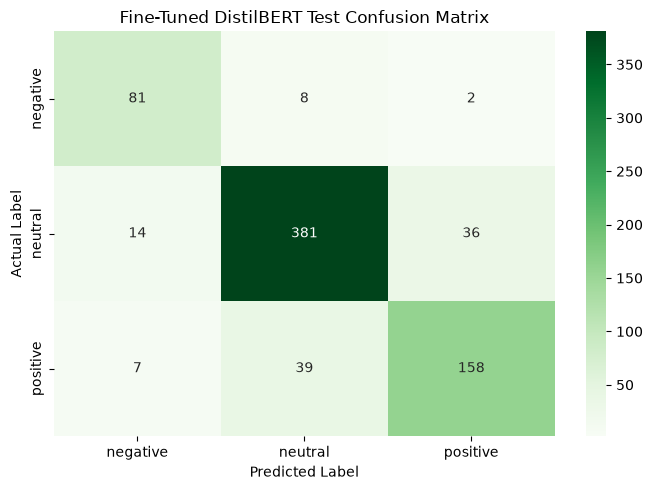

In [7]:

matrix = confusion_matrix(
    finetuned_test_predictions["label"],
    finetuned_test_predictions["predicted_label"],
    labels=LABELS
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=LABELS,
    yticklabels=LABELS
)

plt.title("Fine-Tuned DistilBERT Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    figures_dir / "finetuned_test_confusion_matrix.png",
    dpi=200
)

plt.show()

          Zero-shot baseline  Fine-tuned DistilBERT
Accuracy              0.5000                 0.8540
Macro F1              0.5299                 0.8388


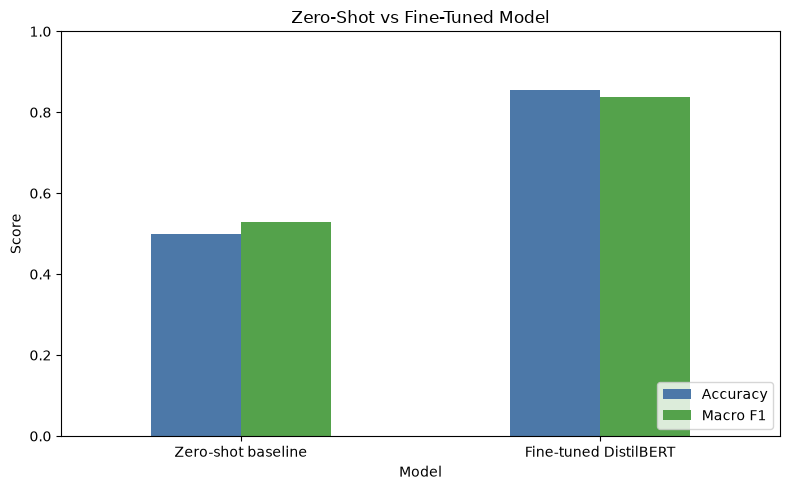

In [8]:

with open(
    metrics_dir / "zero_shot_test_metrics.json",
    "r",
    encoding="utf-8"
) as file:
    zero_shot_metrics = json.load(file)

comparison = pd.DataFrame(
    {
        "Zero-shot baseline": [
            zero_shot_metrics["accuracy"],
            zero_shot_metrics["macro_f1"]
        ],
        "Fine-tuned DistilBERT": [
            finetuned_accuracy,
            finetuned_macro_f1
        ]
    },
    index=["Accuracy", "Macro F1"]
)

comparison = comparison.round(4)

print(comparison)

comparison.T.plot(
    kind="bar",
    figsize=(8, 5),
    ylim=(0, 1),
    color=["#4C78A8", "#54A24B"]
)

plt.title("Zero-Shot vs Fine-Tuned Model")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.tight_layout()

plt.savefig(
    figures_dir / "baseline_vs_finetuned_comparison.png",
    dpi=200
)

plt.show()

In [9]:

errors = finetuned_test_predictions[
    finetuned_test_predictions["label"]
    != finetuned_test_predictions["predicted_label"]
].copy()

errors = errors.sort_values(
    by="confidence",
    ascending=False
)

print("Fine-tuned model errors:", len(errors))

display(
    errors[
        [
            "sentence",
            "label",
            "predicted_label",
            "confidence"
        ]
    ].head(10)
)

Fine-tuned model errors: 106


,sentence,label,predicted_label,confidence
271,The shopping center will have a prime location...,positive,neutral,0.971527
722,"As a result , the distribution companies will ...",positive,neutral,0.966900
282,"There are companies , which are ready to inves...",positive,neutral,0.959526
216,A tinyurl link takes users to a scamming site ...,negative,neutral,0.958812
515,Airbus has 100 firm orders for the A350 and 89...,positive,neutral,0.955655
53,Finnish food industry companies HK Ruokatalo a...,positive,neutral,0.955358
341,Raisio 's malting capacity was in full use in ...,positive,neutral,0.948973
275,The circuit 's overall production rate on a we...,positive,neutral,0.948906
513,"We can choose the most efficient , best overal...",positive,neutral,0.943158
379,A new Kveyt light variety of Suomalainen Pekon...,positive,neutral,0.937619


In [10]:

final_metrics = {
    "model": "distilbert-base-uncased fine-tuned on Financial PhraseBank",
    "evaluation_split": "held-out test set",
    "num_examples": int(len(finetuned_test_predictions)),
    "accuracy": round(float(finetuned_accuracy), 4),
    "macro_f1": round(float(finetuned_macro_f1), 4),
    "per_class_f1": {
        label: round(
            float(finetuned_report[label]["f1-score"]),
            4
        )
        for label in LABELS
    }
}

with open(
    metrics_dir / "finetuned_test_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_metrics, file, indent=2)

finetuned_test_predictions.to_csv(
    predictions_dir / "finetuned_test_predictions.csv",
    index=False
)

errors.to_csv(
    predictions_dir / "finetuned_test_errors.csv",
    index=False
)

print(final_metrics)
print("\nSaved final metrics, predictions, errors, and plots.")

{'model': 'distilbert-base-uncased fine-tuned on Financial PhraseBank', 'evaluation_split': 'held-out test set', 'num_examples': 726, 'accuracy': 0.854, 'macro_f1': 0.8388, 'per_class_f1': {'negative': 0.8394, 'neutral': 0.8871, 'positive': 0.79}}

Saved final metrics, predictions, errors, and plots.
